In [47]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, classification_report

In [48]:
df = pd.read_csv('500hits.csv', encoding='latin-1')
df

,PLAYER,YRS,G,AB,R,H,2B,3B,HR,RBI,BB,SO,SB,CS,BA,HOF
0,Ty Cobb,24,3035,11434,2246,4189,724,295,117,726,1249,357,892,178,0.366,1
1,Stan Musial,22,3026,10972,1949,3630,725,177,475,1951,1599,696,78,31,0.331,1
2,Tris Speaker,22,2789,10195,1882,3514,792,222,117,724,1381,220,432,129,0.345,1
3,Derek Jeter,20,2747,11195,1923,3465,544,66,260,1311,1082,1840,358,97,0.310,1
4,Honus Wagner,21,2792,10430,1736,3430,640,252,101,0,963,327,722,15,0.329,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
460,Jim Wynn,15,1920,6653,1105,1665,285,39,291,964,1224,1427,225,101,0.250,0
461,Jorge Posada,17,1829,6092,900,1664,379,10,275,1065,936,1453,20,21,0.273,0
462,Brady Anderson,15,1834,6499,1062,1661,338,67,210,761,960,1190,315,100,0.256,0
463,Cookie Rojas,16,1822,6309,714,1660,254,25,54,593,396,489,74,68,0.263,0


In [49]:
df = df.drop(['PLAYER', 'CS'], axis=1)
x, y = df.iloc[: :-1], df.iloc[:, -1]
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=11)

In [57]:
class GaussianNB:
    
    def fit(self, x, y):
        x, y = np.array(x), np.array(y)
        self.classes = np.unique(y)
        self.priors = []
        self.means = []
        self.variances = []
        
        for clas in self.classes:
            self.priors.append(np.mean(y == clas))
            class_data = np.array(x[y == clas])
            means = np.mean(class_data, axis=0)
            self.means.append(means)
            self.variances.append(np.mean((class_data - means)**2, axis=0) + 1e-9)

    def predict(self, x):
        x = np.array(x)
        log_posteriors = []
        for i in range(len(self.classes)):
            log_prior = np.log(self.priors[i])
            numerator = -((x - self.means[i])**2) / (2 * self.variances[i])
            denominator = np.log(np.sqrt(2 * np.pi * self.variances[i]))
            log_likelihood = np.sum(numerator - denominator, axis=1)
            log_posteriors.append(log_prior + log_likelihood)
        return self.classes[np.argmax(log_posteriors, axis=0)]

In [58]:
gnb = GaussianNB()
gnb.fit(x_train, y_train)

0.9247311827956989


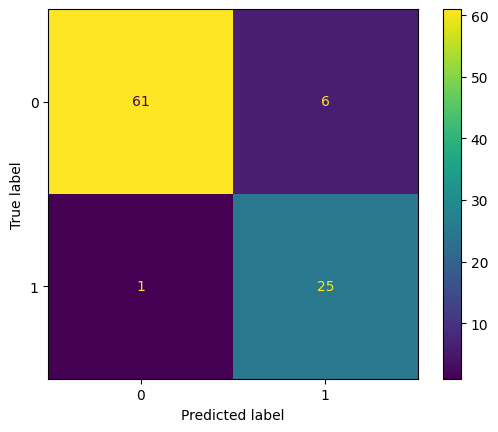

In [59]:
y_pred = gnb.predict(x_test)
print(np.mean(y_test == y_pred))
ConfusionMatrixDisplay(confusion_matrix(y_test, y_pred)).plot()

In [55]:
gnb.predict([[]])

array([0])